# Day 08. Exercise 05
# Clustering

## 0. Imports

In [93]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.cluster import DBSCAN

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

## 1. Preprocessing

1. Read the file [`regression.csv`](https://drive.google.com/file/d/1fzOPkuXoxLleOsvNVCT0m-LKxlid33ma/view?usp=sharing) to a dataframe.
2. Remove the `pageviews`, we will cluster the users only by the number of the commits and their average difference.

In [94]:
df = pd.read_csv('../data/regression.csv')

In [95]:
df = df.drop(columns=['pageviews'])
df.head()

,uid,num_commits,AVG(diff)
0,user_1,62,-64.400000
1,user_10,20,-74.800000
2,user_14,61,-159.000000
3,user_17,51,-61.600000
4,user_18,5,-5.666667


## 2. KMeans

1. Check the documentation about how this algorithm works.
2. Use this algorithm to create clusters, use `random_state=21` and `n_clusters=3`.
3. Visualize the data on a `scatter plot`.
4. Try different values of `n_clusters` and see how your plot will change.
5. Calculate the `silhouette_score` (check the docs about the metric).

In [96]:
X = df.drop(columns=['uid'])

In [97]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [98]:
kmeans = KMeans(n_clusters=3, random_state=21, n_init='auto')
clusters = kmeans.fit_predict(X_scaled)

df['cluster'] = clusters

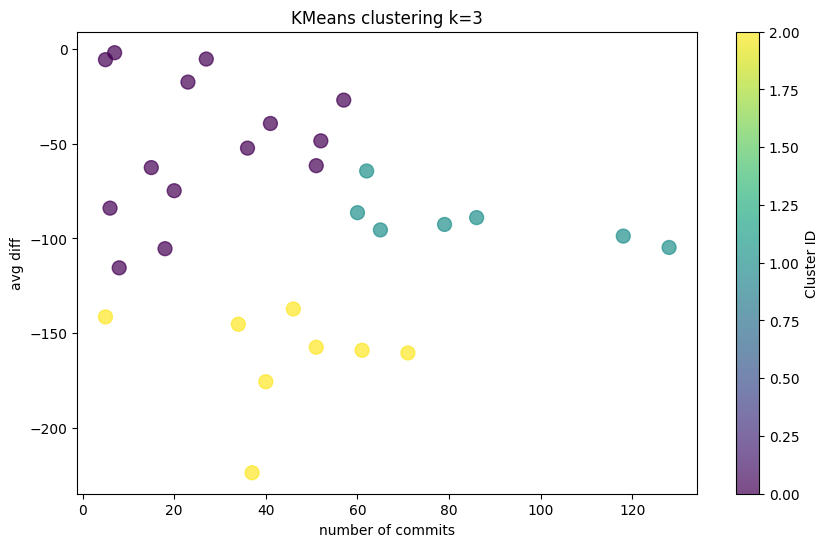

In [99]:
plt.figure(figsize=(10, 6))

plt.scatter(df['num_commits'], df['AVG(diff)'], c=df['cluster'], cmap='viridis', s=100, alpha=0.7)
plt.title('KMeans clustering k=3')
plt.xlabel('number of commits')
plt.ylabel('avg diff')
plt.colorbar(label='Cluster ID')

plt.show()

In [100]:
score = silhouette_score(X_scaled, clusters)
score

0.40476277097754615

### few good experements

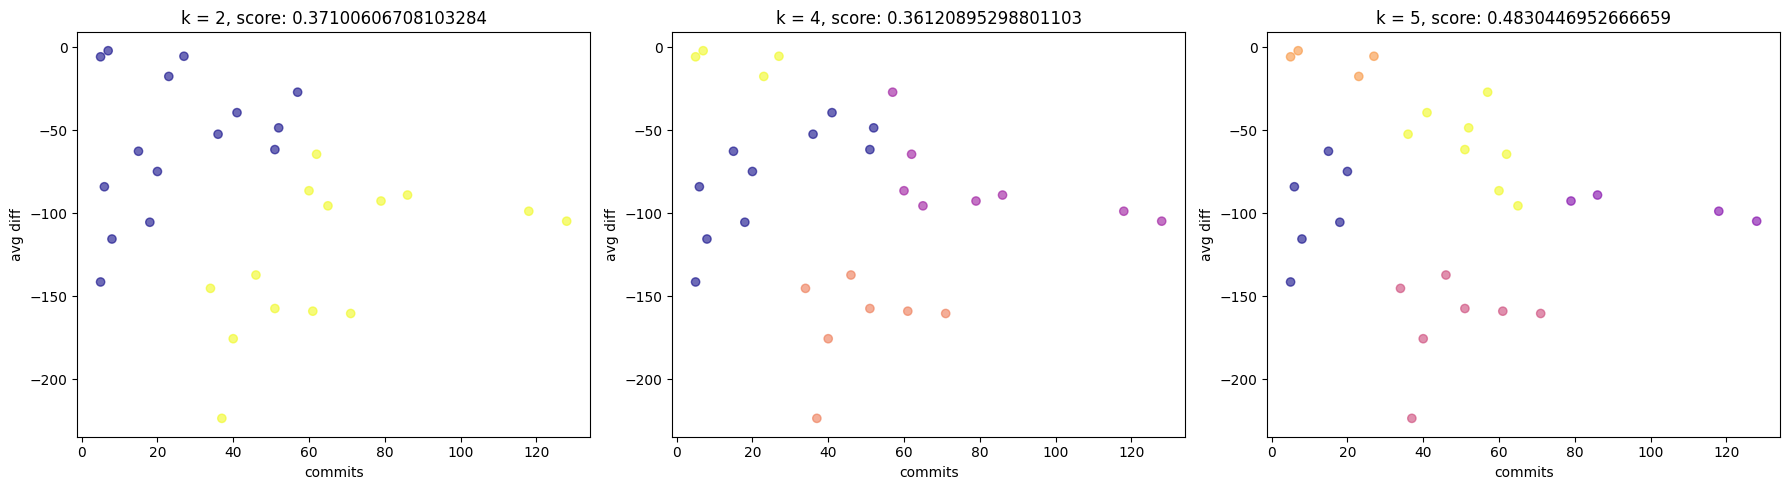

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
k_values = [2, 4, 5]

for i, k in enumerate(k_values):
    km = KMeans(n_clusters=k, random_state=21, n_init='auto')
    labels = km.fit_predict(X_scaled)
    
    axes[i].scatter(df['num_commits'], df['AVG(diff)'], c=labels, cmap='plasma', alpha=0.6)
    axes[i].set_title(f'k = {k}, score: {silhouette_score(X_scaled, labels)}')
    axes[i].set_xlabel('commits')
    axes[i].set_ylabel('avg diff')

plt.tight_layout()
plt.show()

## 3. DBSCAN

1. Check the documentation about how this algorithm works.
2. Use this algorithm to create clusters with `eps=20` and `min_samples=2`.
3. Visualize the data on a `scatter plot`.
4. Try different values of `eps` and `min_samples` and see how your plot will change.
5. Calculate the `silhouette_score` (check the docs about the metric).

In [102]:
X = df[['num_commits', 'AVG(diff)']]

In [103]:
dbscan = DBSCAN(eps=20, min_samples=2)
clusters_db = dbscan.fit_predict(X)

In [104]:
df['cluster_db'] = clusters_db

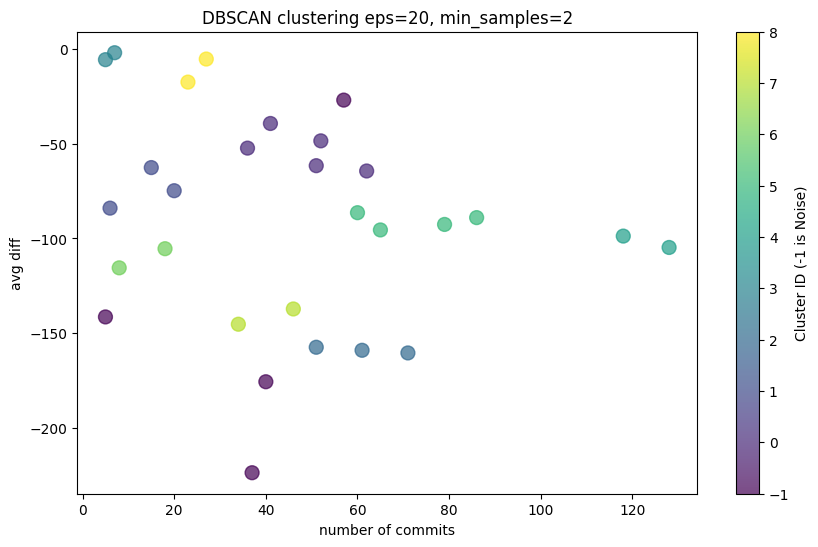

In [105]:
plt.figure(figsize=(10, 6))

plt.scatter(df['num_commits'], df['AVG(diff)'], c=df['cluster_db'], cmap='viridis', s=100, alpha=0.7)
plt.title('DBSCAN clustering eps=20, min_samples=2')
plt.xlabel('number of commits')
plt.ylabel('avg diff')
plt.colorbar(label='Cluster ID (-1 is Noise)')

plt.show()

In [106]:
unique_labels = set(clusters_db)
score = silhouette_score(X, clusters_db)
score

0.38339641455696616

### few good experements

config eps=10, min_samples=2 found 2 clusters.
config eps=20, min_samples=5 found 1 clusters.
config eps=30, min_samples=2 found 2 clusters.


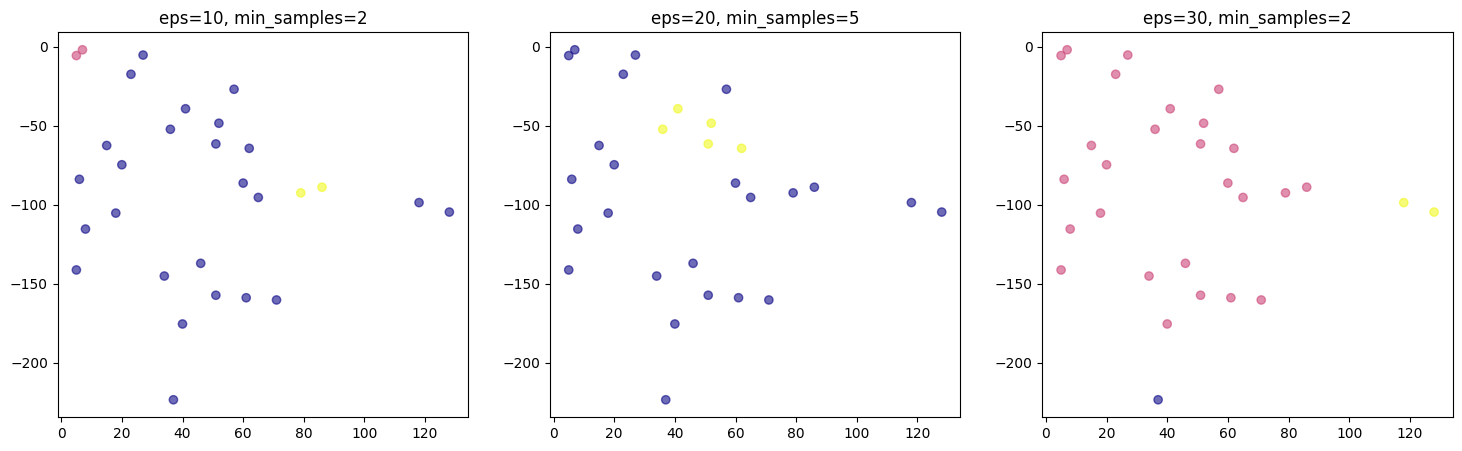

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
configs = [(10, 2), (20, 5), (30, 2)]

for i, (e, m) in enumerate(configs):
    db = DBSCAN(eps=e, min_samples=m)
    labels = db.fit_predict(X)
    
    axes[i].scatter(df['num_commits'], df['AVG(diff)'], c=labels, cmap='plasma', alpha=0.6)
    axes[i].set_title(f'eps={e}, min_samples={m}')
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"config eps={e}, min_samples={m} found {n_clusters} clusters.")

plt.show()

## 4. Hierarchical (AgglomerativeClustering)

1. Use this algorithm to create clusters with `n_clusters=5`.
2. Visualize the data on a `scatter plot`.
3. Try different values of `n_clusters` and see how your plot will change.
4. Calculate the `silhouette_score`.
5. Visualize the `dendrogram`.

In [108]:
X = df[['num_commits', 'AVG(diff)']]

In [109]:
agg_clust = AgglomerativeClustering(n_clusters=5)
clusters_agg = agg_clust.fit_predict(X)

In [110]:
df['cluster_agg'] = clusters_agg

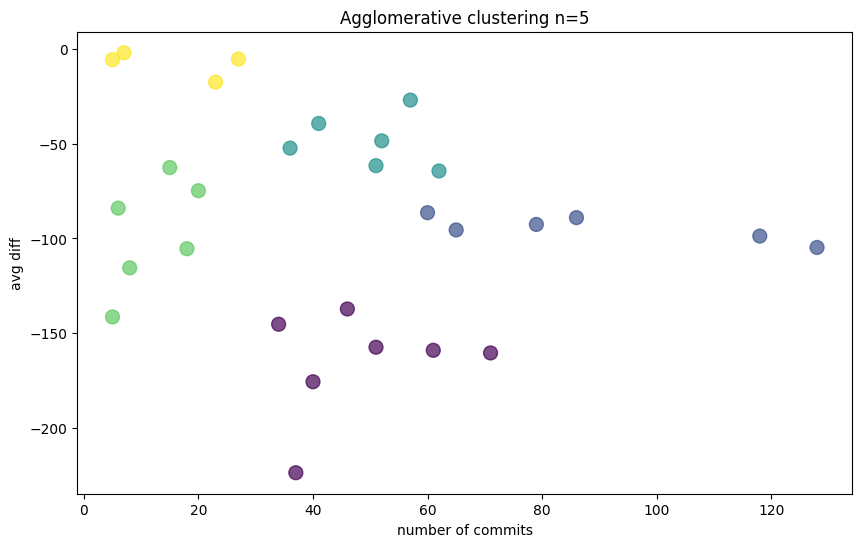

In [111]:
plt.figure(figsize=(10, 6))
plt.scatter(df['num_commits'], df['AVG(diff)'], c=df['cluster_agg'], cmap='viridis', s=100, alpha=0.7)
plt.title('Agglomerative clustering n=5')
plt.xlabel('number of commits')
plt.ylabel('avg diff')
plt.show()

In [112]:
score = silhouette_score(X, clusters_agg)
score

0.46383015199381467

### few good experements

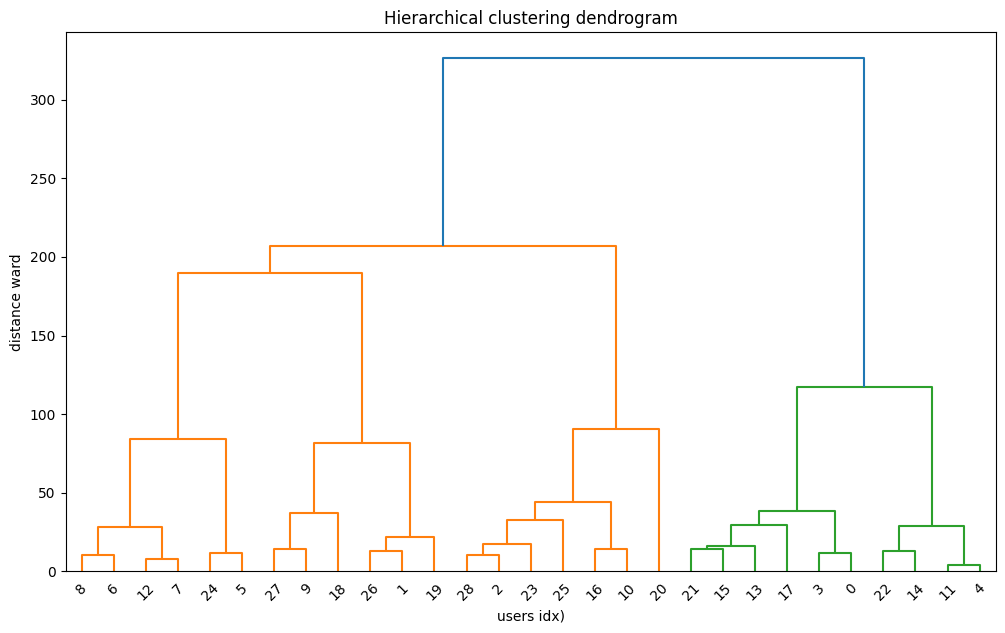

In [113]:
plt.figure(figsize=(12, 7))

linked = linkage(X, method='ward')

dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)

plt.title('Hierarchical clustering dendrogram')
plt.xlabel('users idx)')
plt.ylabel('distance ward')

plt.axhline(y=350, c='k', ls='--', lw=2) 
plt.show()

## 5. Function

Write a function that:
1. Takes as arguments: model class of clustering, its parameters, the name of the parameter for optimization, the range of the parameter values to try.
2. Tries different values from the given parameter range and calculates the `silhouette_score` for each value from the range.
3. Finds out the best value for the parameter in the range.
4. Returns two subplots:


- - the first shows how the `silhouette_score` changes depending on the value of the parameter,
- - the second visualizes the data on a `scatter plot` using the clustering model with the best value of the parameter.

In [114]:
def optimize_clustering(model_class, param_name, param_range, X, other_params={}):
    scores = []

    for val in param_range:
        # словарь параметров
        current_params = other_params.copy()
        current_params[param_name] = val
        
        # model init
        model = model_class(**current_params)
        
        # обучаем и получаем метки
        labels = model.fit_predict(X)

        unique_labels = set(labels)
        if len(unique_labels) > 1 and not (len(unique_labels) == 2 and -1 in unique_labels):
            score = silhouette_score(X, labels)
        else:
            score = -1.0
        scores.append(score)
    
    best_score = max(scores)
    best_param_val = param_range[scores.index(best_score)]

    print(f"Best {param_name}: {best_param_val}, silhouette score: {best_score}")

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    # graph 1 silhoutte from features
    axes[0].plot(param_range, scores, marker='o', color='purple')
    axes[0].set_title(f'Optimization of {param_name}')
    axes[0].set_xlabel(param_name)
    axes[0].set_ylabel('Silhouette Score')
    axes[0].grid(True)

    best_params = other_params.copy()
    best_params[param_name] = best_param_val
    best_model = model_class(**best_params)
    best_labels = best_model.fit_predict(X)

    # graph 2 scatter plot with best param param pam
    scatter = axes[1].scatter(X.iloc[:, 0], X.iloc[:, 1], c=best_labels, cmap='viridis', s=100, alpha=0.7)
    axes[1].set_title(f'Best clustering {param_name}={best_param_val}')
    axes[1].set_xlabel(X.columns[0])
    axes[1].set_ylabel(X.columns[1])
    plt.colorbar(scatter, ax=axes[1], label='Cluster ID')

    plt.show()

Best n_clusters: 8, silhouette score: 0.48638087320227846


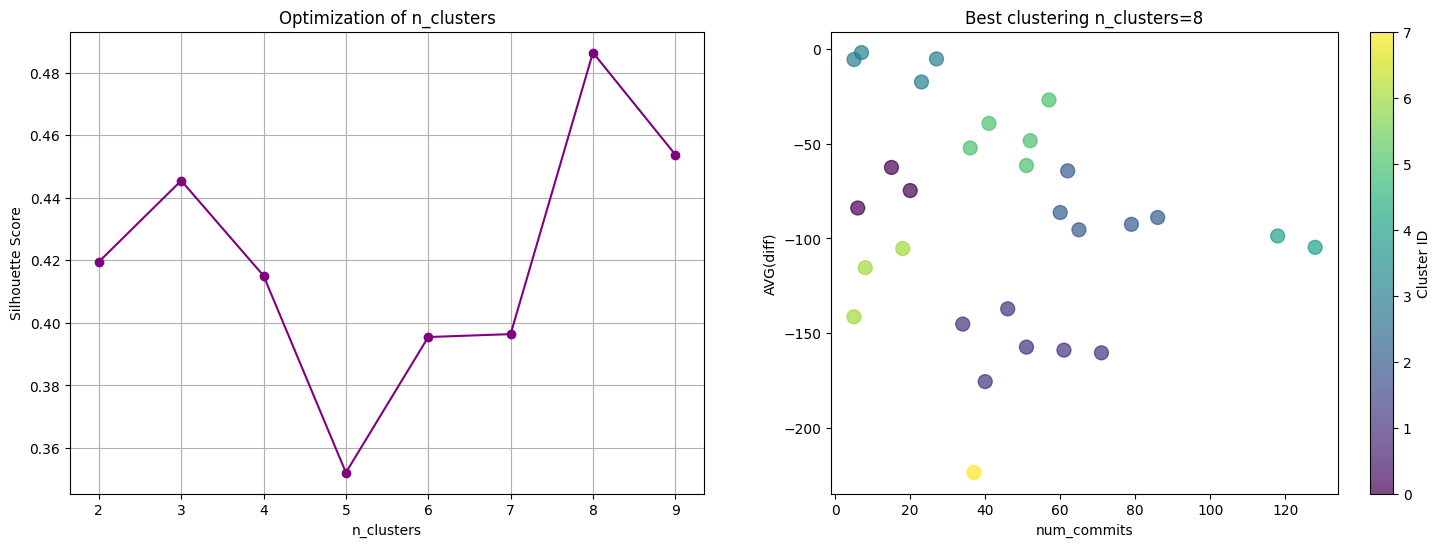

Best eps: 21, silhouette score: 0.4646046547648843


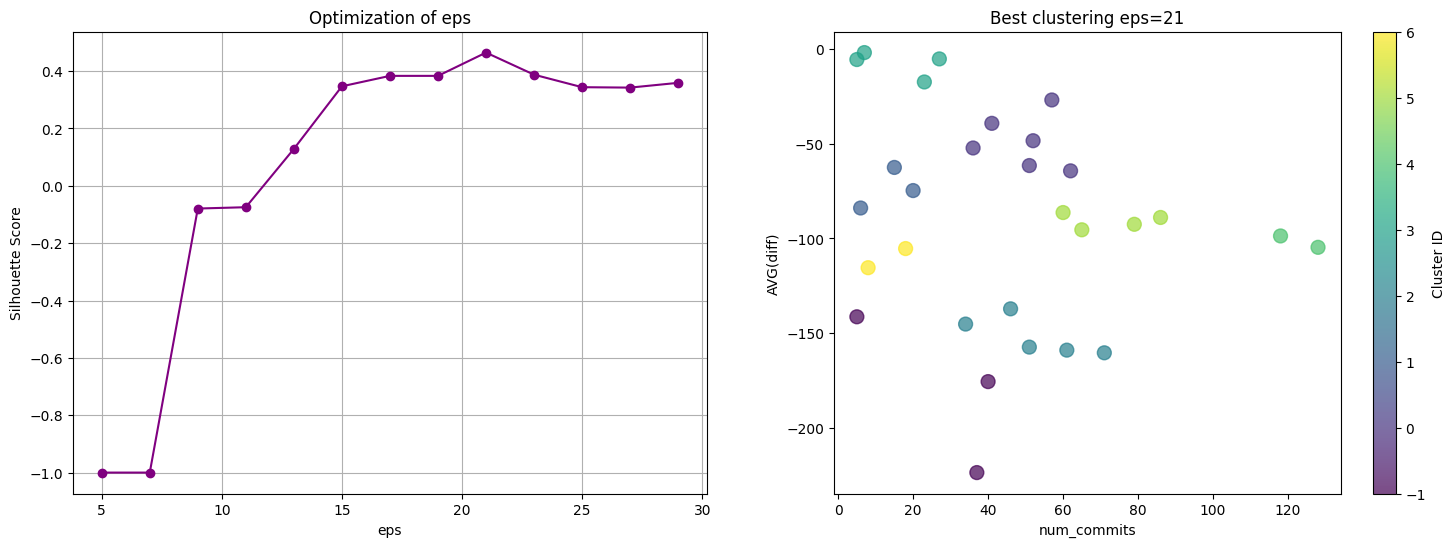

Best n_clusters: 8, silhouette score: 0.50779855565622


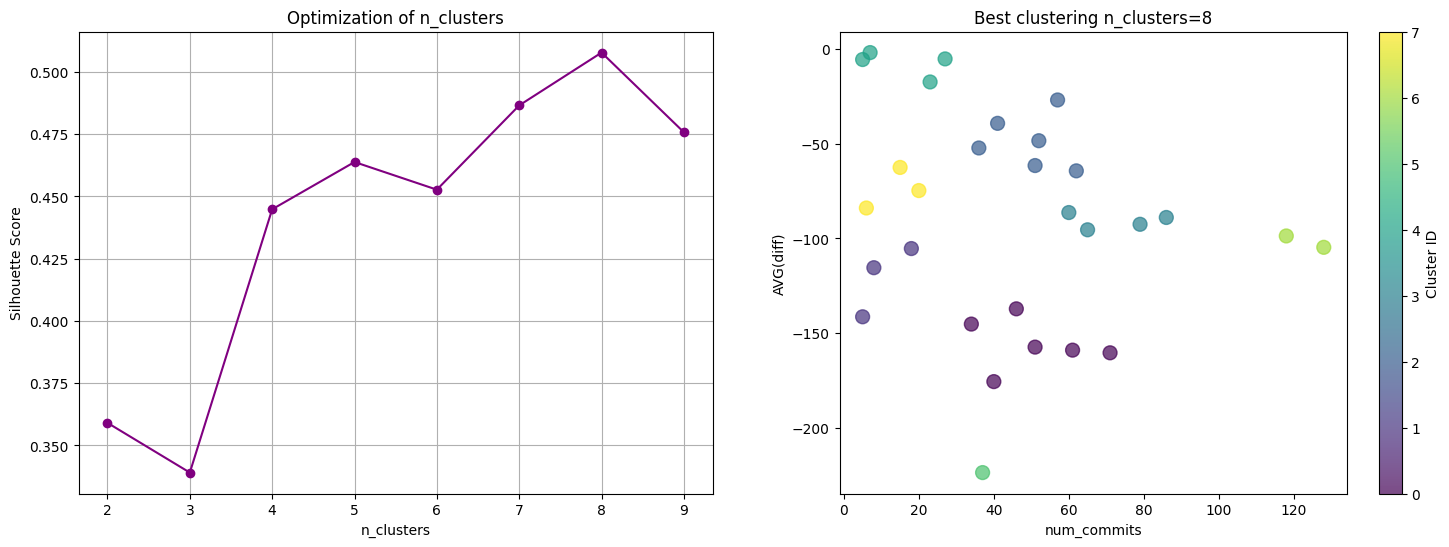

Best min_samples: 1, silhouette score: 0.4322483665424573


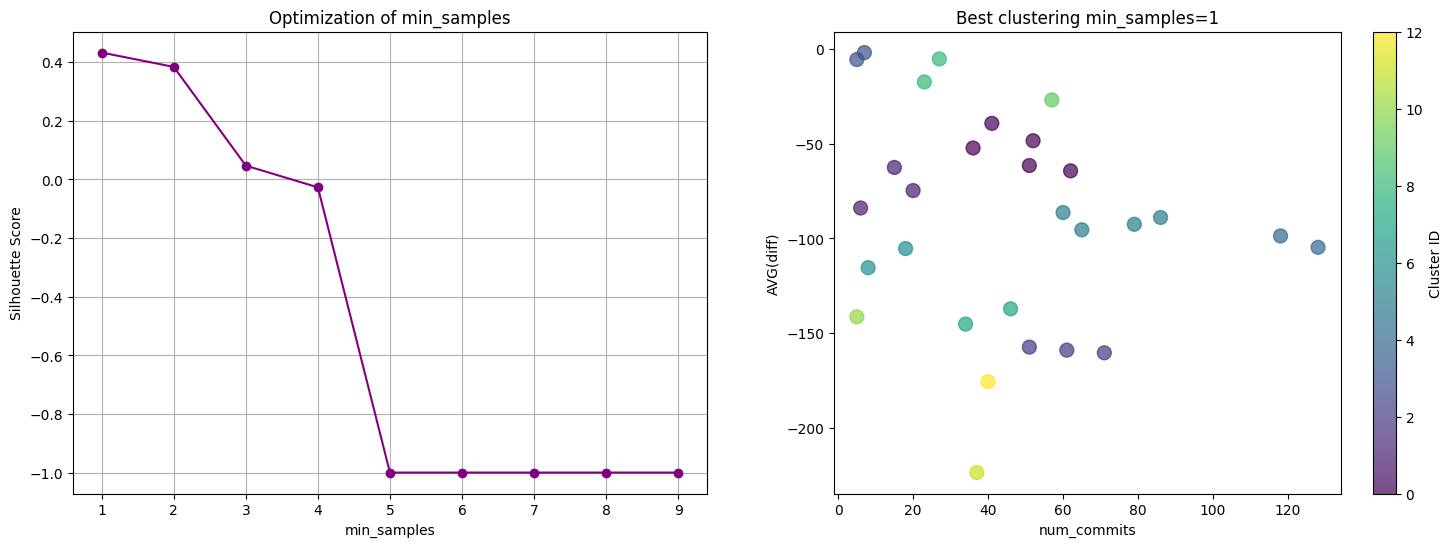

In [115]:
optimize_clustering(
    model_class=KMeans,
    param_name='n_clusters',
    param_range=range(2, 10),
    X=X,
    other_params={'random_state': 21, 'n_init': 'auto'}
)

optimize_clustering(
    model_class=DBSCAN,
    param_name='eps',
    param_range=range(5, 30, 2),
    X=X,
    other_params={'min_samples': 2}
)

optimize_clustering(
    model_class=AgglomerativeClustering,
    param_name='n_clusters',
    param_range=range(2, 10),
    X=X,
    other_params={}
)

optimize_clustering(
    model_class=DBSCAN,
    param_name='min_samples',
    param_range=range(1, 10),
    X=X,
    other_params={'eps': 20}
)